# Statistical Description of Brain Tumor MRI Dataset
This notebook covers the extraction of pixel, histogram, and color features from images, and plots the distributions.

In [1]:
pip install opencv-python seaborn scipy tqdm ipywidgets

  Using cached numpy-2.5.4-cp312-cp312-win_amd64.whl.metadata (6.6 kB)
  Using cached numpy-2.2.6-cp312-cp312-win_amd64.whl.metadata (60 kB)
Using cached numpy-2.2.6-cp312-cp312-win_amd64.whl (12.6 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gensim 4.3.3 requires numpy<2.0,>=1.18.5, but you have numpy 2.2.6 which is incompatible.
numba 0.60.0 requires numpy<2.1,>=1.22, but you have numpy 2.2.6 which is incompatible.


In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis, entropy
from pathlib import Path
from tqdm.notebook import tqdm

sns.set_theme(style="whitegrid")

### 💡 Explanation: Extracting Math from Each Image
**What we are doing to the dataset here:**
We take *one single image at a time*, convert it to grayscale, and extract important statistical features.
- **Pixels (Mean, Variance, Skewness, Kurtosis):** These tell us how bright the image is overall, how spread out the pixel intensities are, and if the image leans towards being too dark or too light.
- **Histogram (Entropy, Contrast):** These look at the *texture* and *complexity*. For instance, high entropy means a highly detailed image.
- **Color Moments (R, G, B):** This looks at the red, green, and blue channels separately.

In [2]:
def compute_image_statistics(img_path):
    img_bgr = cv2.imread(str(img_path))
    if img_bgr is None: return None
        
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    
    mean_val = np.mean(img_gray)
    median_val = np.median(img_gray)
    var_val = np.var(img_gray)
    std_val = np.std(img_gray)
    skew_val = skew(img_gray, axis=None)
    kurt_val = kurtosis(img_gray, axis=None)
    
    hist_counts, _ = np.histogram(img_gray.ravel(), bins=256, range=(0, 256))
    hist_prob = hist_counts / hist_counts.sum()
    prob_non_zero = hist_prob[hist_prob > 0]
    entropy_val = entropy(prob_non_zero, base=2)
    energy_val = np.sum(hist_prob ** 2)
    contrast_val = std_val
    
    r, g, b = img_rgb[:,:,0], img_rgb[:,:,1], img_rgb[:,:,2]
    
    return {
        'filename': img_path.name,
        'class': img_path.parent.name,
        'split': img_path.parent.parent.name.capitalize(),
        'height': img_gray.shape[0],
        'width': img_gray.shape[1],
        'mean': mean_val,
        'median': median_val,
        'variance': var_val,
        'std_dev': std_val,
        'skewness': skew_val,
        'kurtosis': kurt_val,
        'entropy': entropy_val,
        'energy': energy_val,
        'contrast': contrast_val,
        'r_mean': np.mean(r), 'g_mean': np.mean(g), 'b_mean': np.mean(b),
        'r_std': np.std(r), 'g_std': np.std(g), 'b_std': np.std(b),
        'r_skew': skew(r, axis=None), 'g_skew': skew(g, axis=None), 'b_skew': skew(b, axis=None)
    }

### 💡 Explanation: Processing the Entire Dataset Folder
**What we are doing to the dataset here:**
1. We use a loop to systematically open the `Training` and `Testing` folders.
2. We find every image in every sub-tumor category.
3. We run the `compute_image_statistics` function on each image to build our massive `df` table.

In [3]:
def process_dataset(dataset_path):
    dataset_dir = Path(dataset_path)
    all_stats = []
    sample_images = {'Training': None, 'Testing': None}
    splits = ['Training', 'Testing', 'training', 'testing']
    
    for split_name in splits:
        split_dir = dataset_dir / split_name
        if not split_dir.exists() or not split_dir.is_dir(): continue
            
        for class_dir in split_dir.iterdir():
            if class_dir.is_dir():
                for img_path in tqdm(list(class_dir.rglob('*')), desc=f"{class_dir.name}"):
                    if img_path.suffix.lower() in ['.jpg', '.jpeg', '.png']:
                        stats = compute_image_statistics(img_path)
                        if stats:
                            all_stats.append(stats)
                            if sample_images[stats['split']] is None:
                                sample_images[stats['split']] = img_path
                                
    return pd.DataFrame(all_stats), sample_images

### 💡 Explanation: Setting up the Visual Graphs
**What we are doing to the dataset here:**
We are preparing the canvas to visualize the numerical dataset table.
- Second, it creates Density Curves (KDE plots) layering the Training dataset over the Testing dataset to ensure our databases share similar structures!

In [10]:
def plot_visualizations(df, sample_images):
    for split, img_path in sample_images.items():
        if img_path is None: continue
        img_bgr = cv2.imread(str(img_path))
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
        
        plt.figure(figsize=(16, 4))
        plt.subplot(1, 4, 1); plt.imshow(img_rgb); plt.title(f"{split} (RGB)"); plt.axis('off')
        plt.subplot(1, 4, 2); plt.imshow(img_gray, cmap='gray'); plt.title(f"{split} (Gray)"); plt.axis('off')
        
        plt.subplot(1, 4, 3)
        for i, col in enumerate(('r', 'g', 'b')):
            hist = cv2.calcHist([img_rgb], [i], None, [256], [0, 256])
            plt.plot(hist, color=col, alpha=0.7)
        plt.title("RGB Histogram")
        
        plt.subplot(1, 4, 4)
        plt.plot(cv2.calcHist([img_gray], [0], None, [256], [0, 256]), color='black')
        plt.title("Grayscale Histogram")
        plt.show()
        
    features = ['mean', 'variance', 'entropy', 'contrast']
    plt.figure(figsize=(14, 10))
    for i, f in enumerate(features, 1):
        plt.subplot(2, 2, i)
        sns.kdeplot(data=df, x=f, hue="split", fill=True, common_norm=False, alpha=0.5)
        plt.title(f"Distribution of {f.capitalize()}")
    plt.tight_layout(); plt.show()

### 💡 Explanation: Generating the Numerical Data Summary
**What we are doing to the dataset here:**
We are printing the raw math (`mean`, `std`, `min`, `max`) for three groups: Combined, Training, Testing. Then we calculate absolute % differences to verify consistency.

In [11]:
def generate_summary(df):
    cols = ['mean', 'median', 'variance', 'std_dev', 'skewness', 'kurtosis', 'entropy', 'energy', 'contrast', 'r_mean', 'g_mean', 'b_mean']
    from IPython.display import display
    
    print("=== COMBINED DATASET ===")
    display(df[cols].describe().T[['mean', 'std', 'min', 'max']])
    
    train_df = df[df['split'] == 'Training']
    test_df = df[df['split'] == 'Testing']
    
    if not train_df.empty:
        print("\n=== TRAINING DATASET ===")
        train_sum = train_df[cols].describe().T[['mean', 'std', 'min', 'max']]
        display(train_sum)
        
    if not test_df.empty:
        print("\n=== TESTING DATASET ===")
        test_sum = test_df[cols].describe().T[['mean', 'std', 'min', 'max']]
        display(test_sum)
        
    if not train_df.empty and not test_df.empty:
        print("\n=== DIFFERENCES (TRAIN VS TEST) ===")
        diff = train_sum['mean'] - test_sum['mean']
        display(pd.DataFrame({'Train Mean': train_sum['mean'], 'Test Mean': test_sum['mean'], 'Abs Diff': diff, '% Diff': (diff / test_sum['mean']) * 100}).round(3))

### 💡 Explanation: Main Execution
This points to the active folder and triggers the massive extraction process to build our `df`!

<>:1: SyntaxWarning: invalid escape sequence '\d'
<>:1: SyntaxWarning: invalid escape sequence '\d'
C:\Users\aryas\AppData\Local\Temp\ipykernel_26392\344183524.py:1: SyntaxWarning: invalid escape sequence '\d'
  dataset_path = "C:\dev\Tumor_Classification\Brain_Tumor_MRI_Dataset\Brain_Tumor_MRI_Dataset" # Point this strictly to your extracted dataset folder


glioma:   0%|          | 0/1400 [00:00<?, ?it/s]

meningioma:   0%|          | 0/1400 [00:00<?, ?it/s]

notumor:   0%|          | 0/1400 [00:00<?, ?it/s]

pituitary:   0%|          | 0/1400 [00:00<?, ?it/s]

glioma:   0%|          | 0/400 [00:00<?, ?it/s]

... (15 outputs left out)


=== TESTING DATASET ===


,mean,std,min,max
mean,49.847146,18.967707,15.267933,137.764303
median,35.714062,30.096416,0.000000,159.000000
variance,2530.960990,1495.734857,441.887986,10466.884675
std_dev,48.551621,13.181631,21.021132,102.307794
skewness,0.957638,0.413452,-0.623712,2.882984
kurtosis,0.738098,1.305209,-1.689972,10.329090
entropy,5.914360,0.790243,3.052637,7.729755
energy,0.071077,0.066583,0.005197,0.482096
contrast,48.551621,13.181631,21.021132,102.307794
r_mean,49.843392,18.962448,15.267933,137.764303



=== DIFFERENCES (TRAIN VS TEST) ===


,Train Mean,Test Mean,Abs Diff,% Diff
mean,46.904,49.847,-2.943,-5.904
median,32.056,35.714,-3.658,-10.242
variance,2352.795,2530.961,-178.166,-7.039
std_dev,46.761,48.552,-1.791,-3.688
skewness,0.997,0.958,0.040,4.130
kurtosis,0.818,0.738,0.080,10.876
entropy,5.867,5.914,-0.047,-0.799
energy,0.069,0.071,-0.002,-3.344
contrast,46.761,48.552,-1.791,-3.688
r_mean,46.903,49.843,-2.940,-5.899


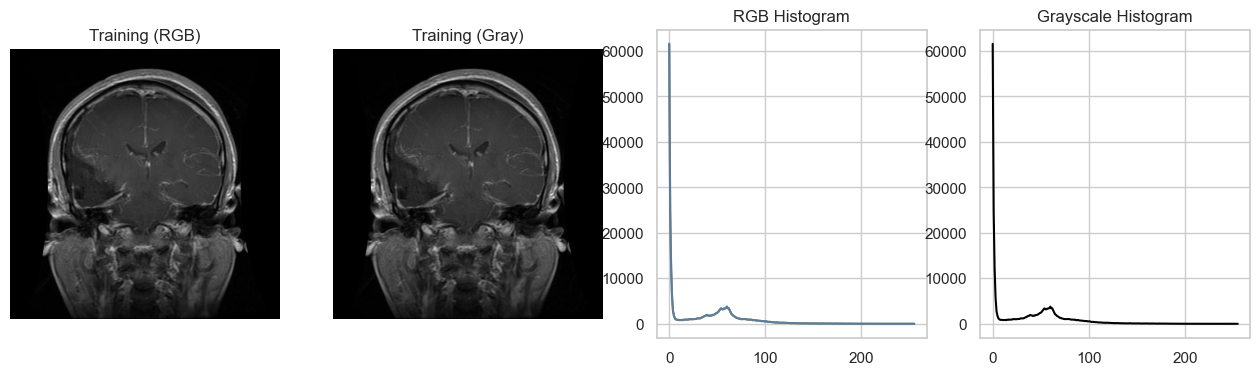

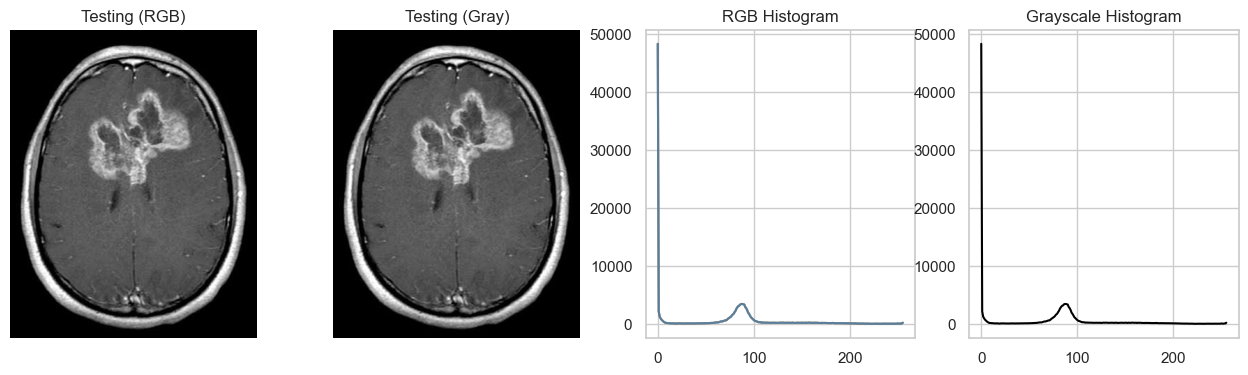

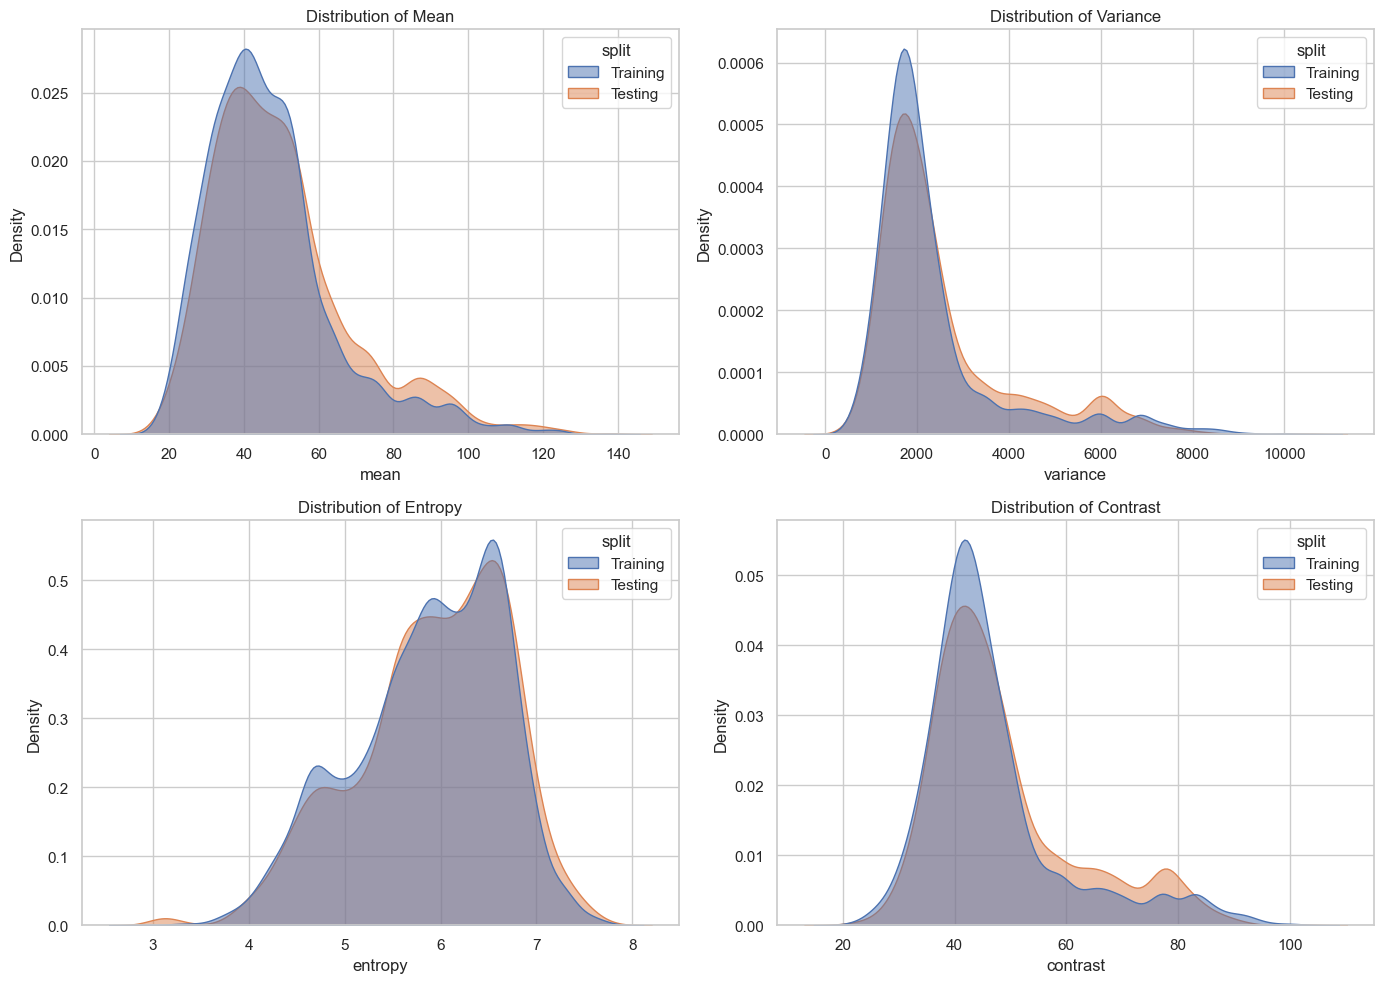

In [8]:
dataset_path = "C:\dev\Tumor_Classification\Brain_Tumor_MRI_Dataset\Brain_Tumor_MRI_Dataset" # Point this strictly to your extracted dataset folder
df, sample_images = process_dataset(dataset_path)

if not df.empty:
    print(f"Successfully extracted features from {len(df)} images.")
    generate_summary(df)
    plot_visualizations(df, sample_images)

### 💡 Explanation: Visualizing the Complete Dataset
The Complete Dataset represents all images combined (both Training and Testing) to provide a global view of the data before the model split.

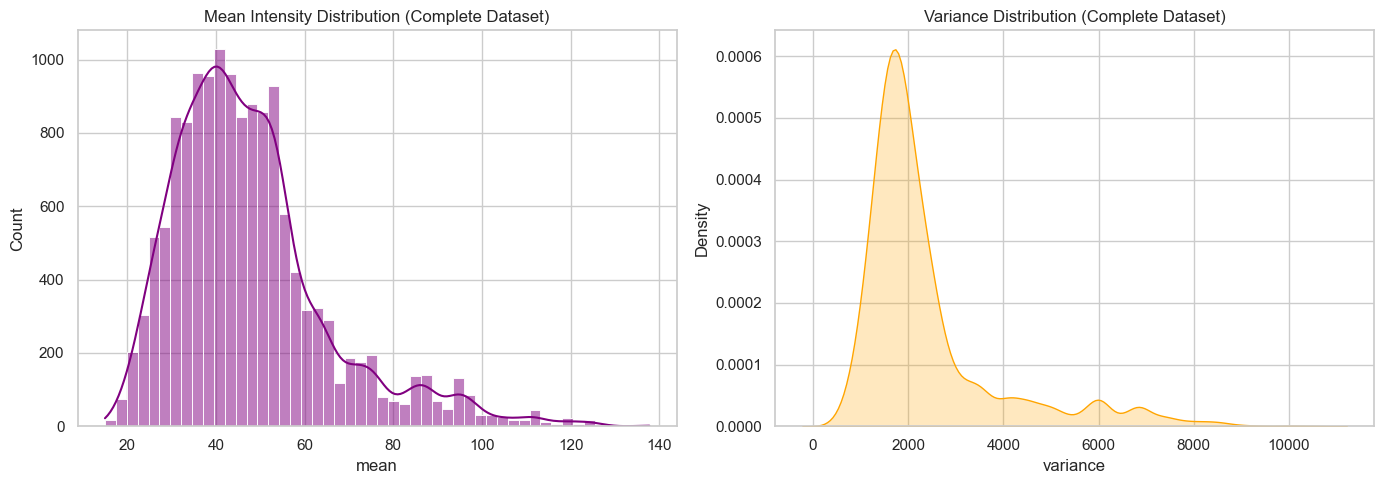

In [12]:
if not df.empty:
    plt.figure(figsize=(14, 5))
    plt.subplot(1, 2, 1)
    sns.histplot(df['mean'], kde=True, color='purple', bins=50)
    plt.title("Mean Intensity Distribution (Complete Dataset)")

    plt.subplot(1, 2, 2)
    sns.kdeplot(df['variance'], fill=True, color='orange')
    plt.title("Variance Distribution (Complete Dataset)")

    plt.tight_layout()
    plt.show()

### 💡 Explanation: Individual Visualization of Training vs Testing Datasets
We separate the dataframe into `train_df` (Training) and `test_df` (Testing).
- **Training** teaches the model. The feature distributions ensure our model learns generic features.
- **Testing** evaluates the model. Feature distributions here should ideally be identical to the Training dataset.

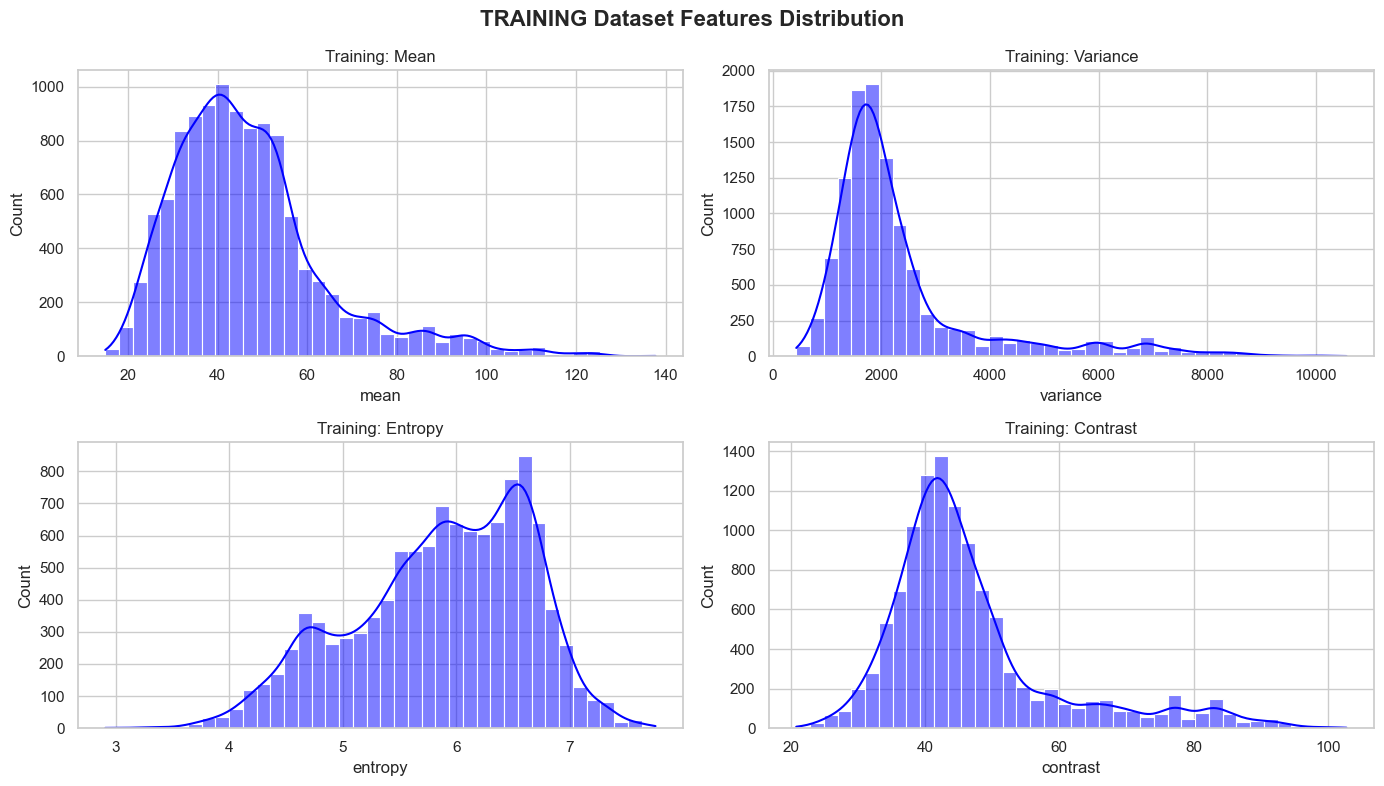

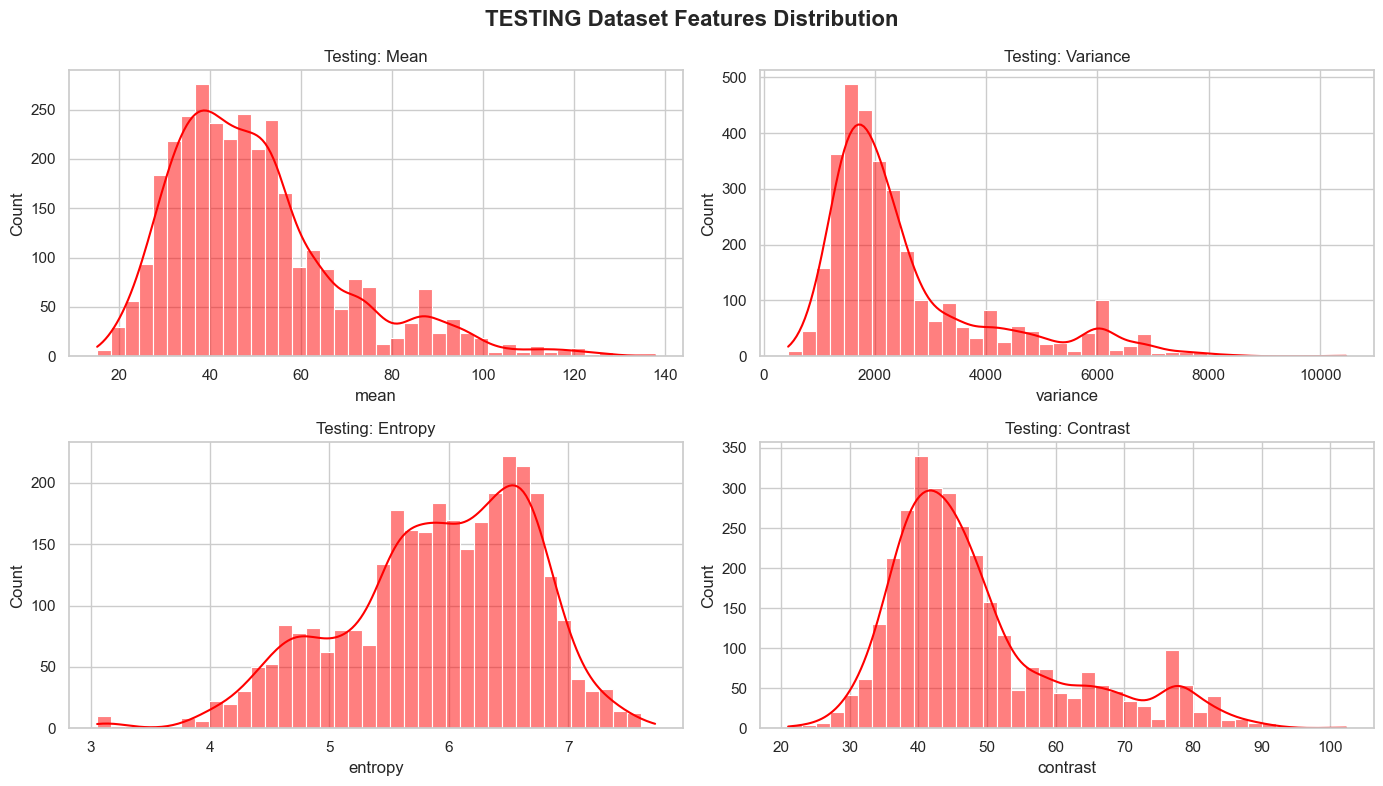

In [13]:
if not df.empty:
    train_df = df[df['split'] == 'Training']
    test_df = df[df['split'] == 'Testing']
    features_to_plot = ['mean', 'variance', 'entropy', 'contrast']

    plt.figure(figsize=(14, 8))
    plt.suptitle("TRAINING Dataset Features Distribution", fontsize=16, fontweight='bold')
    for i, feature in enumerate(features_to_plot, 1):
        plt.subplot(2, 2, i)
        sns.histplot(train_df[feature], kde=True, color='blue', bins=40)
        plt.title(f"Training: {feature.capitalize()}")
    plt.tight_layout(); plt.show()

    plt.figure(figsize=(14, 8))
    plt.suptitle("TESTING Dataset Features Distribution", fontsize=16, fontweight='bold')
    for i, feature in enumerate(features_to_plot, 1):
        plt.subplot(2, 2, i)
        sns.histplot(test_df[feature], kde=True, color='red', bins=40)
        plt.title(f"Testing: {feature.capitalize()}")
    plt.tight_layout(); plt.show()